# Training VGG16

Fine-tuning VGG16 (pretrained ImageNet) untuk 31 kelas rempah, dengan `training.py` dan konfigurasi yang
sama dengan arsitektur lain. Training dijalankan lewat `python train_vgg16.py`; notebook ini memuat
hasilnya dari `results/vgg16/`.

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

import data_pipeline as dp
import training as tr

MODEL_NAME = "vgg16"

C_TRAIN, C_VAL, C_ACCENT = "#2a78d6", "#eb6834", "#1baf7a"
C_GRID, C_TEXT = "#d8d7d2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6,
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_TEXT,
    "xtick.color": C_TEXT, "ytick.color": C_TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
})

dp.seed_everything(dp.SEED)
DEVICE = dp.get_device()
print(f"Device: {DEVICE}")
print(f"Torch : {torch.__version__}")

Device: mps
Torch : 2.15.0


## 2. Tentang VGG16

- **Kernel 3×3 seragam** — tumpukan 3×3 punya receptive field setara kernel besar, dengan parameter lebih
  sedikit dan non-linearitas lebih banyak.
- **Susunan** — 13 konvolusi dalam 5 blok (64 → 512 filter) dipisah max-pooling, lalu 3 layer FC
  (4096 → 4096 → 31) dengan dropout 0.5.
- **Parameter terkonsentrasi di FC** — FC pertama saja ±102.8 M dari total 134.4 M.
- **Biaya** — ±15.5 GFLOPs per citra; tanpa batch normalization dan skip connection.

In [2]:
baris = []
for name in tr.ARCHITECTURES:
    m = tr.build_model(name, num_classes=31, pretrained=False)
    info = tr.count_parameters(m)
    baris.append({"arsitektur": name,
                  "params (M)": round(info["total_params"] / 1e6, 1),
                  "ukuran (MB)": round(info["size_mb"], 1)})
    del m

konteks = pd.DataFrame(baris).sort_values("params (M)")
print(konteks.to_string(index=False))
print("\n(Baris selain vgg16 hanya konteks ukuran; pelatihannya bagian anggota kelompok lain.)")

     arsitektur  params (M)  ukuran (MB)
   mobilenet_v2         2.3          9.1
efficientnet_b0         4.0         16.2
       resnet18        11.2         44.8
       resnet50        23.6         94.3
        alexnet        57.1        228.5
          vgg16       134.4        537.6

(Baris selain vgg16 hanya konteks ukuran; pelatihannya bagian anggota kelompok lain.)


## 3. Data & Model

In [3]:
CONFIG = tr.TrainConfig(
    epochs=5,
    lr=1e-4,
    weight_decay=1e-4,
    batch_size=32,
    patience=5,
    augment="basic",
    use_class_weights=True,
)

loaders, ds = dp.build_dataloaders(
    batch_size=CONFIG.batch_size, num_workers=2, augment=CONFIG.augment
)
classes = ds["train"].classes

print(f"train/val/test : {len(ds['train'])}/{len(ds['val'])}/{len(ds['test'])}")
print(f"kelas          : {len(classes)}")
print(f"batch per epoch: {len(loaders['train'])}")
print(f"\nHyperparameter (harus sama untuk semua arsitektur yang dibandingkan):")
for k, v in vars(CONFIG).items():
    print(f"  {k:20s}: {v}")

train/val/test : 4219/904/905
kelas          : 31
batch per epoch: 131

Hyperparameter (harus sama untuk semua arsitektur yang dibandingkan):
  epochs              : 5
  lr                  : 0.0001
  weight_decay        : 0.0001
  batch_size          : 32
  label_smoothing     : 0.0
  patience            : 5
  seed                : 42
  augment             : basic
  use_class_weights   : True
  extra               : {}


In [4]:
model = tr.build_model(MODEL_NAME, num_classes=len(classes), pretrained=True)
info = tr.count_parameters(model)

print(f"{MODEL_NAME}: {info['total_params']:,} parameter ({info['total_params']/1e6:.2f} M), "
      f"{info['size_mb']:.1f} MB")
print(f"\nLayer klasifikasi setelah diganti:\n{model.classifier}")

print(f"\nParameter yang dilatih: {info['trainable_params']:,} (seluruh jaringan, fine-tuning penuh)")

vgg16: 134,387,551 parameter (134.39 M), 537.6 MB

Layer klasifikasi setelah diganti:
Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=31, bias=True)
)

Parameter yang dilatih: 134,387,551 (seluruh jaringan, fine-tuning penuh)


## 4. Training

- AdamW (lr 1e-4, weight decay 1e-4) + cosine annealing, 5 epoch, batch 32
- Cross-entropy berbobot kelas untuk menangani imbalance (1.73×)
- Checkpoint terbaik dipilih dari **val macro-F1**, agar kelas kecil berbobot sama

`RETRAIN = False` memuat hasil tersimpan, `True` melatih ulang.

In [5]:
RETRAIN = False

sudah_ada = (Path("results") / MODEL_NAME / "history.json").exists()

if RETRAIN or not sudah_ada:
    if not sudah_ada:
        print("Hasil training belum ada. Disarankan jalankan dulu dari terminal:\n"
              "    python train_vgg16.py\n"
              "Melanjutkan dengan training dari notebook...\n")
    t0 = time.perf_counter()
    hasil = tr.fit(model, loaders, ds, model_name=MODEL_NAME, config=CONFIG, device=DEVICE)
    print(f"\nTotal waktu training: {(time.perf_counter() - t0)/60:.1f} menit")
else:
    hasil = tr.load_run(MODEL_NAME, model, device=DEVICE)
    print(f"Memuat hasil training tersimpan (dari train_vgg16.py).")
    print(f"Jalankan ulang dengan RETRAIN = True kalau ingin melatih dari awal.\n")

print(f"Epoch dijalankan : {len(hasil['history'])}")
print(f"Epoch terbaik    : {hasil['best_epoch']} (val macro-F1 {hasil['best_val_macro_f1']:.4f})")
print(f"Waktu training   : {hasil['total_train_time_s']/60:.1f} menit")
print(f"Checkpoint       : {hasil['checkpoint']}")

Memuat hasil training tersimpan (dari train_vgg16.py).
Jalankan ulang dengan RETRAIN = True kalau ingin melatih dari awal.

Epoch dijalankan : 5
Epoch terbaik    : 5 (val macro-F1 0.9358)
Waktu training   : 17.3 menit
Checkpoint       : /Users/pangeran/Documents/Telkom University/semester 5/visi komputer/TugasCNN/IndonesiaSpicesProject_CNN/models/vgg16_best.pt


### 4.1 Kurva Belajar

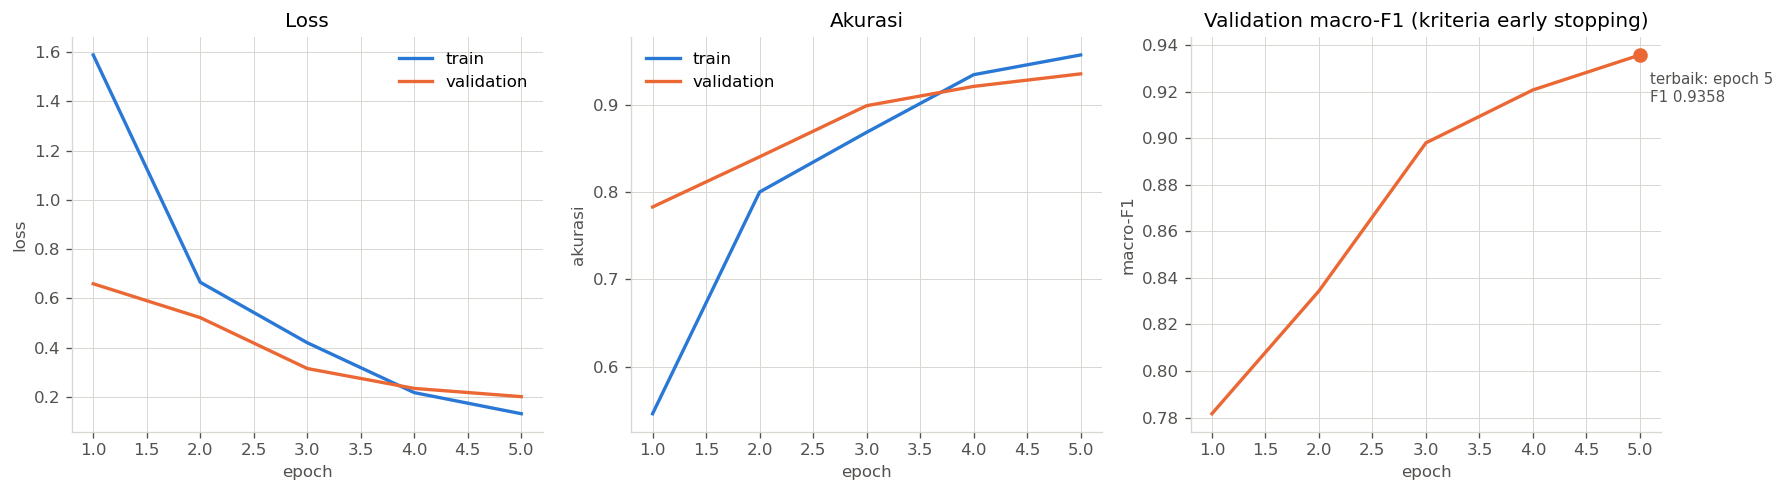

 epoch  train_loss  train_acc  val_loss  val_acc  val_macro_f1  train_time_s
     1      1.5876     0.5460    0.6596   0.7832        0.7816      203.3363
     2      0.6656     0.8003    0.5223   0.8407        0.8344      198.1079
     3      0.4204     0.8688    0.3159   0.8993        0.8980      193.0957
     4      0.2181     0.9349    0.2352   0.9215        0.9208      194.4994
     5      0.1325     0.9575    0.2018   0.9358        0.9358      192.7177

Gap train-val akurasi di epoch terbaik: +0.0217
Gap besar (>0.10) menandakan overfitting -> pertimbangkan augment='strong'.


In [6]:
hist = pd.DataFrame(hasil["history"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(hist["epoch"], hist["train_loss"], color=C_TRAIN, lw=2, label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], color=C_VAL, lw=2, label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend(frameon=False)

axes[1].plot(hist["epoch"], hist["train_acc"], color=C_TRAIN, lw=2, label="train")
axes[1].plot(hist["epoch"], hist["val_acc"], color=C_VAL, lw=2, label="validation")
axes[1].set(xlabel="epoch", ylabel="akurasi", title="Akurasi")
axes[1].legend(frameon=False)

axes[2].plot(hist["epoch"], hist["val_macro_f1"], color=C_VAL, lw=2)
best = hasil["best_epoch"]
best_f1 = hasil["best_val_macro_f1"]
axes[2].scatter([best], [best_f1], color=C_VAL, s=60, zorder=5)
axes[2].annotate(f"terbaik: epoch {best}\nF1 {best_f1:.4f}",
                 xy=(best, best_f1), xytext=(6, -28), textcoords="offset points",
                 fontsize=9, color=C_TEXT)
axes[2].set(xlabel="epoch", ylabel="macro-F1", title="Validation macro-F1 (kriteria early stopping)")

plt.tight_layout()
plt.show()

print(hist[["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1", "train_time_s"]]
      .round(4).to_string(index=False))

gap = hist.loc[hist["epoch"] == best, "train_acc"].iloc[0] - hist.loc[hist["epoch"] == best, "val_acc"].iloc[0]
print(f"\nGap train-val akurasi di epoch terbaik: {gap:+.4f}")
print("Gap besar (>0.10) menandakan overfitting -> pertimbangkan augment='strong'.")

## 5. Evaluasi pada Test Set

Memakai checkpoint terbaik (dipilih dari validation). Test set hanya dipakai di sini.

In [7]:
evalres = tr.evaluate(model, loaders, ds, model_name=MODEL_NAME, hasil_fit=hasil, device=DEVICE)
m = evalres["metrics"]

print(f"=== {MODEL_NAME} — hasil test ===\n")
ringkas = pd.DataFrame([
    ("Accuracy", m["accuracy"]),
    ("Top-5 accuracy", m["top5_accuracy"]),
    ("Precision (macro)", m["precision_macro"]),
    ("Recall (macro)", m["recall_macro"]),
    ("F1 (macro)", m["f1_macro"]),
    ("Precision (weighted)", m["precision_weighted"]),
    ("Recall (weighted)", m["recall_weighted"]),
    ("F1 (weighted)", m["f1_weighted"]),
], columns=["metrik", "nilai"])
print(ringkas.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print(f"\nSelisih val macro-F1 ({hasil['best_val_macro_f1']:.4f}) vs test macro-F1 ({m['f1_macro']:.4f}): "
      f"{m['f1_macro'] - hasil['best_val_macro_f1']:+.4f}")
print(f"Hasil disimpan ke: {evalres['output_dir']}")

=== vgg16 — hasil test ===

              metrik  nilai
            Accuracy 0.9348
      Top-5 accuracy 0.9967
   Precision (macro) 0.9369
      Recall (macro) 0.9344
          F1 (macro) 0.9342
Precision (weighted) 0.9382
   Recall (weighted) 0.9348
       F1 (weighted) 0.9350

Selisih val macro-F1 (0.9358) vs test macro-F1 (0.9342): -0.0016
Hasil disimpan ke: /Users/pangeran/Documents/Telkom University/semester 5/visi komputer/TugasCNN/IndonesiaSpicesProject_CNN/results/vgg16


### 5.1 Metrik per Kelas

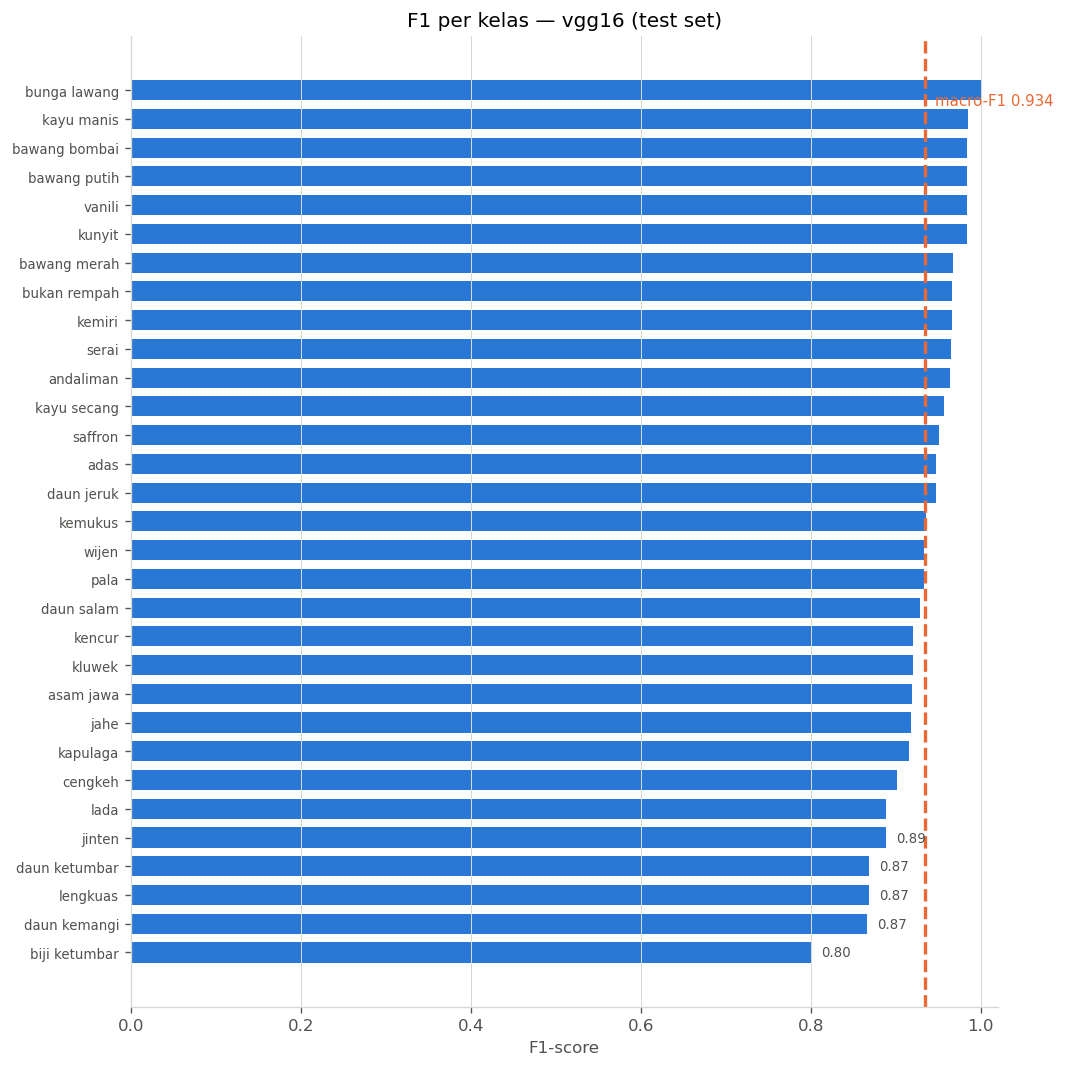

5 kelas terlemah:
        class  precision  recall     f1  support
biji ketumbar     0.7500  0.8571 0.8000       28
 daun kemangi     0.8056  0.9355 0.8657       31
     lengkuas     0.9583  0.7931 0.8679       29
daun ketumbar     0.9583  0.7931 0.8679       29
       jinten     0.8571  0.9231 0.8889       26

5 kelas terkuat:
        class  precision  recall     f1  support
       vanili     0.9688     1.0 0.9841       31
 bawang putih     0.9688     1.0 0.9841       31
bawang bombai     0.9688     1.0 0.9841       31
   kayu manis     0.9697     1.0 0.9846       32
 bunga lawang     1.0000     1.0 1.0000       28


In [8]:
per_class = pd.DataFrame(evalres["per_class"]).sort_values("f1")

fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(per_class))
ax.barh(y, per_class["f1"], color=C_TRAIN, height=0.7)
ax.set_yticks(y)
ax.set_yticklabels(per_class["class"], fontsize=8)
ax.axvline(m["f1_macro"], color=C_VAL, lw=2, ls="--")
ax.annotate(f"macro-F1 {m['f1_macro']:.3f}", xy=(m["f1_macro"], len(per_class) - 1.5),
            xytext=(6, 0), textcoords="offset points", fontsize=9, color=C_VAL)
ax.set(xlabel="F1-score", xlim=(0, 1.02), title=f"F1 per kelas — {MODEL_NAME} (test set)")
ax.grid(axis="y", visible=False)
for i in range(5):
    ax.text(per_class["f1"].iloc[i] + 0.012, i, f"{per_class['f1'].iloc[i]:.2f}",
            va="center", fontsize=8, color=C_TEXT)
plt.tight_layout()
plt.show()

print("5 kelas terlemah:")
print(per_class.head(5)[["class", "precision", "recall", "f1", "support"]]
      .round(4).to_string(index=False))
print("\n5 kelas terkuat:")
print(per_class.tail(5)[["class", "precision", "recall", "f1", "support"]]
      .round(4).to_string(index=False))

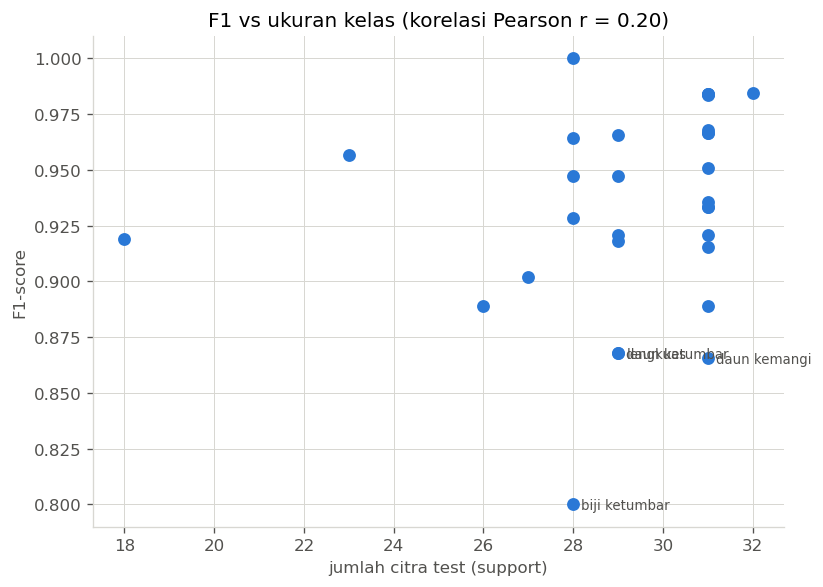

Korelasi support vs F1: r = 0.195
r mendekati 0 berarti kesulitan kelas lebih ditentukan kemiripan visual daripada jumlah data.


In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(per_class["support"], per_class["f1"], color=C_TRAIN, s=45, zorder=3)
for _, r in per_class.head(4).iterrows():
    ax.annotate(r["class"], xy=(r["support"], r["f1"]), xytext=(5, -3),
                textcoords="offset points", fontsize=8, color=C_TEXT)
korelasi = per_class["support"].corr(per_class["f1"])
ax.set(xlabel="jumlah citra test (support)", ylabel="F1-score",
       title=f"F1 vs ukuran kelas (korelasi Pearson r = {korelasi:.2f})")
plt.tight_layout()
plt.show()
print(f"Korelasi support vs F1: r = {korelasi:.3f}")
print("r mendekati 0 berarti kesulitan kelas lebih ditentukan kemiripan visual daripada jumlah data.")

### 5.2 Confusion Matrix

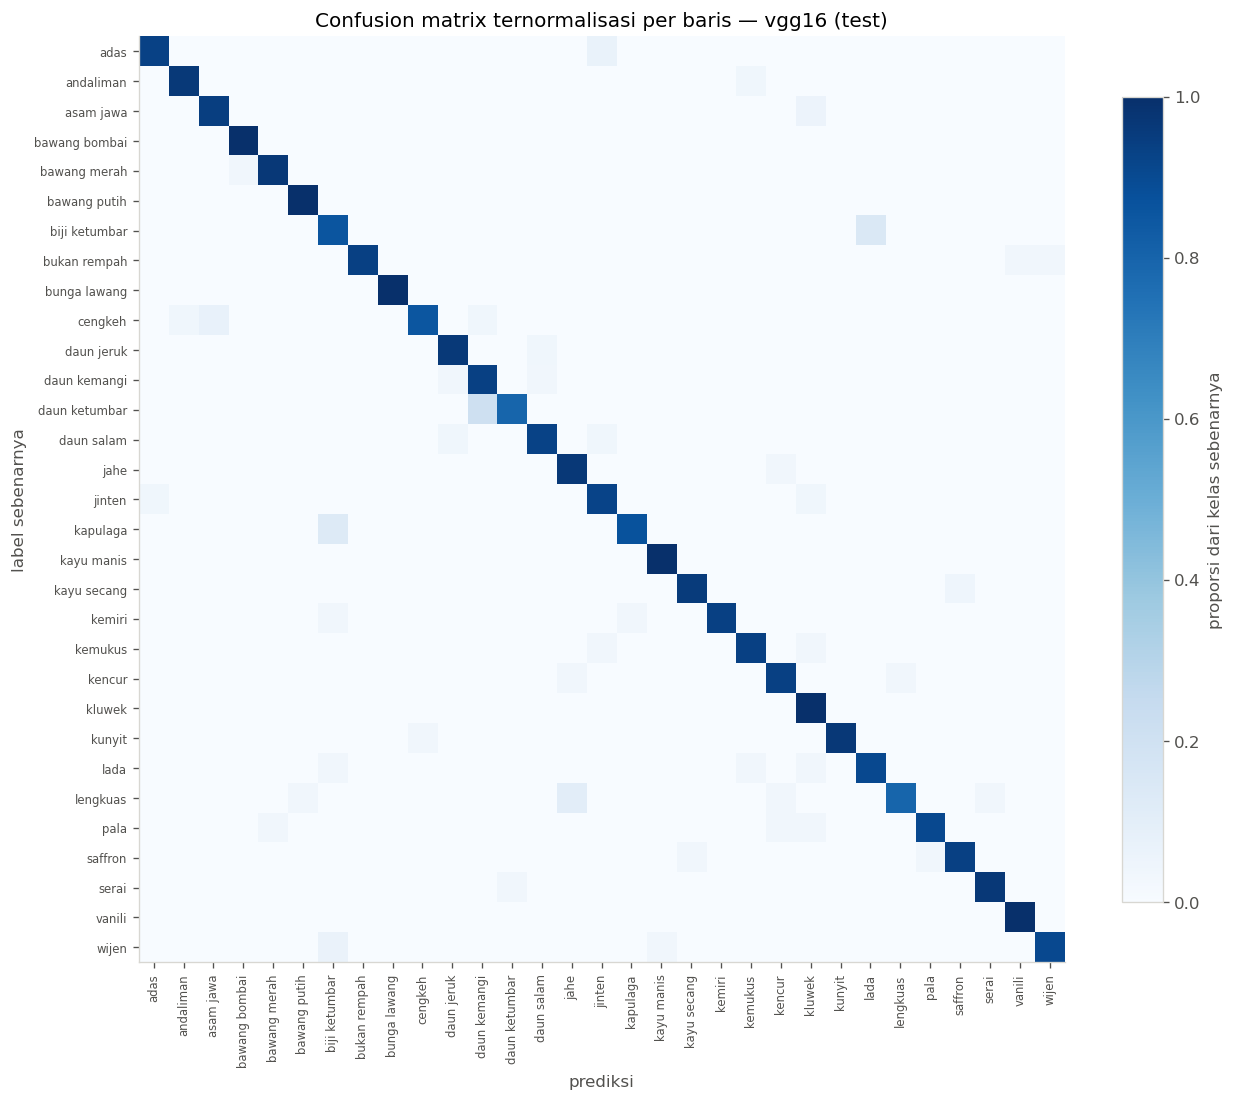

15 kebingungan terbesar:
   sebenarnya    diprediksi  n  proporsi
daun ketumbar  daun kemangi  6     0.207
biji ketumbar          lada  4     0.143
     kapulaga biji ketumbar  4     0.129
     lengkuas          jahe  3     0.103
         adas        jinten  2     0.069
      cengkeh     asam jawa  2     0.074
        wijen biji ketumbar  2     0.065
    andaliman       kemukus  1     0.036
    asam jawa        kluwek  1     0.056
 bawang merah bawang bombai  1     0.032
 bukan rempah        vanili  1     0.032
 bukan rempah         wijen  1     0.032
      cengkeh     andaliman  1     0.037
      cengkeh  daun kemangi  1     0.037
   daun jeruk    daun salam  1     0.036

Total salah klasifikasi: 59 dari 905 citra test


In [10]:
cm = evalres["confusion_matrix"]
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90, fontsize=7)
ax.set_yticklabels(classes, fontsize=7)
ax.set(xlabel="prediksi", ylabel="label sebenarnya",
       title=f"Confusion matrix ternormalisasi per baris — {MODEL_NAME} (test)")
ax.grid(visible=False)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("proporsi dari kelas sebenarnya", color=C_TEXT)
plt.tight_layout()
plt.show()

salah = [(classes[i], classes[j], cm[i, j], cm_norm[i, j])
         for i in range(len(classes)) for j in range(len(classes))
         if i != j and cm[i, j] > 0]
salah.sort(key=lambda t: -t[2])

konfusi = pd.DataFrame(salah[:15], columns=["sebenarnya", "diprediksi", "n", "proporsi"])
print("15 kebingungan terbesar:")
print(konfusi.round(3).to_string(index=False))
print(f"\nTotal salah klasifikasi: {int(cm.sum() - np.trace(cm))} dari {int(cm.sum())} citra test")

### 5.3 Analisis Kesalahan

Jumlah salah: 59 (6.52%)
Rata-rata confidence saat BENAR : 0.9566
Rata-rata confidence saat SALAH : 0.7429

Model yang terkalibrasi baik seharusnya kurang yakin ketika salah.


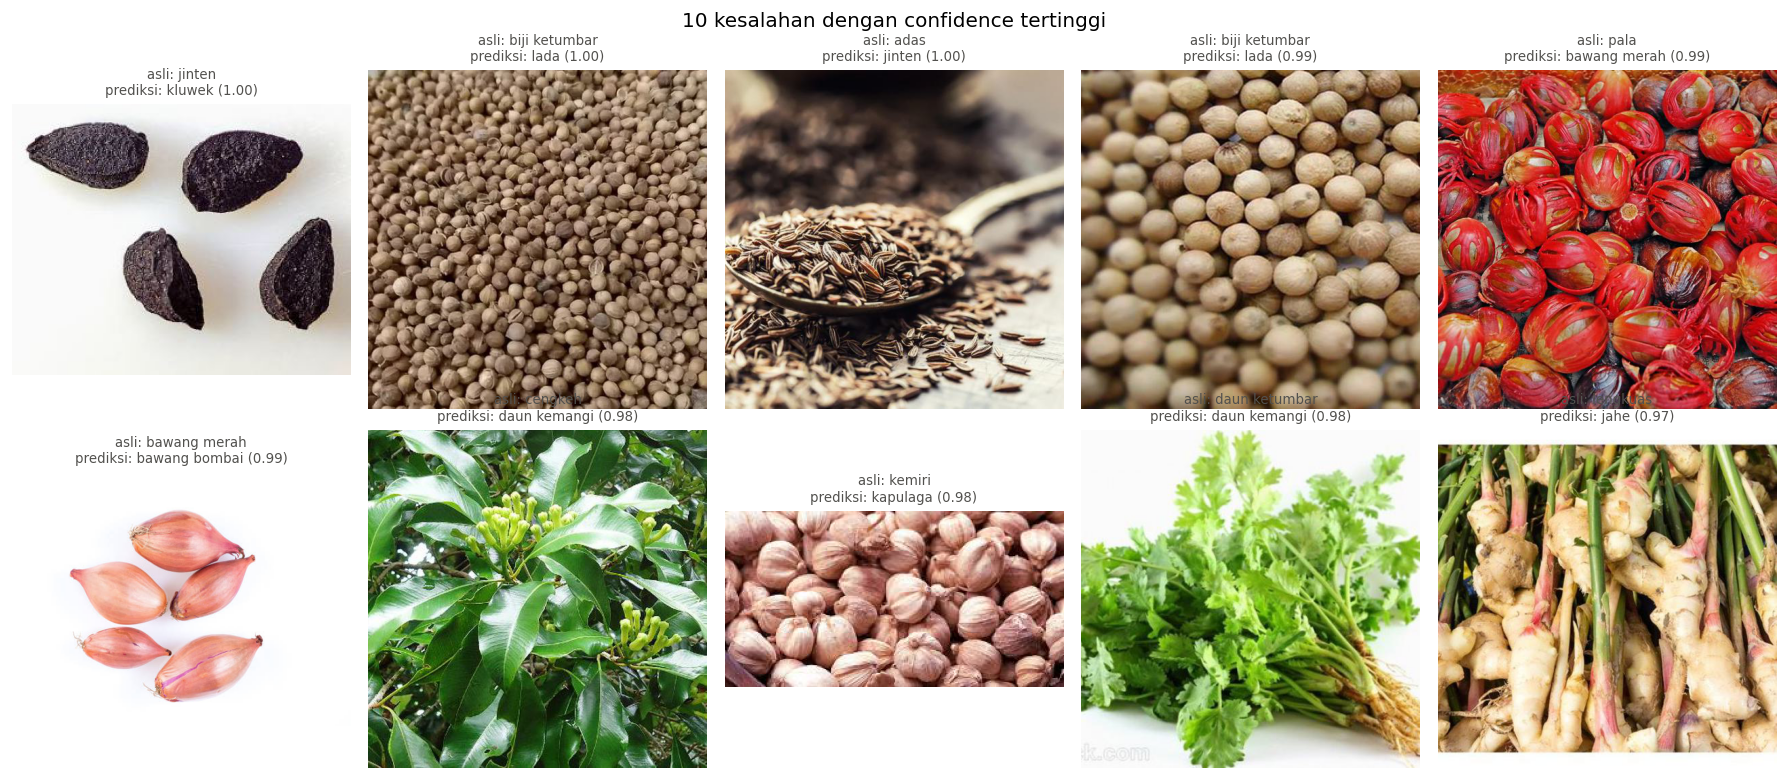

In [11]:
probs, preds, trues = evalres["probs"], evalres["preds"], evalres["trues"]
paths = [p for p, _ in ds["test"].samples]

salah_idx = np.where(preds != trues)[0]
conf = probs[np.arange(len(preds)), preds]

print(f"Jumlah salah: {len(salah_idx)} ({len(salah_idx)/len(preds):.2%})")
print(f"Rata-rata confidence saat BENAR : {conf[preds == trues].mean():.4f}")
print(f"Rata-rata confidence saat SALAH : {conf[salah_idx].mean():.4f}")
print("\nModel yang terkalibrasi baik seharusnya kurang yakin ketika salah.")

urut = salah_idx[np.argsort(-conf[salah_idx])][:10]
fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for ax, i in zip(axes.ravel(), urut):
    ax.imshow(Image.open(paths[i]).convert("RGB"))
    ax.set_title(f"asli: {classes[trues[i]]}\nprediksi: {classes[preds[i]]} ({conf[i]:.2f})",
                 fontsize=8, color=C_TEXT)
    ax.axis("off")
fig.suptitle("10 kesalahan dengan confidence tertinggi")
plt.tight_layout()
plt.show()

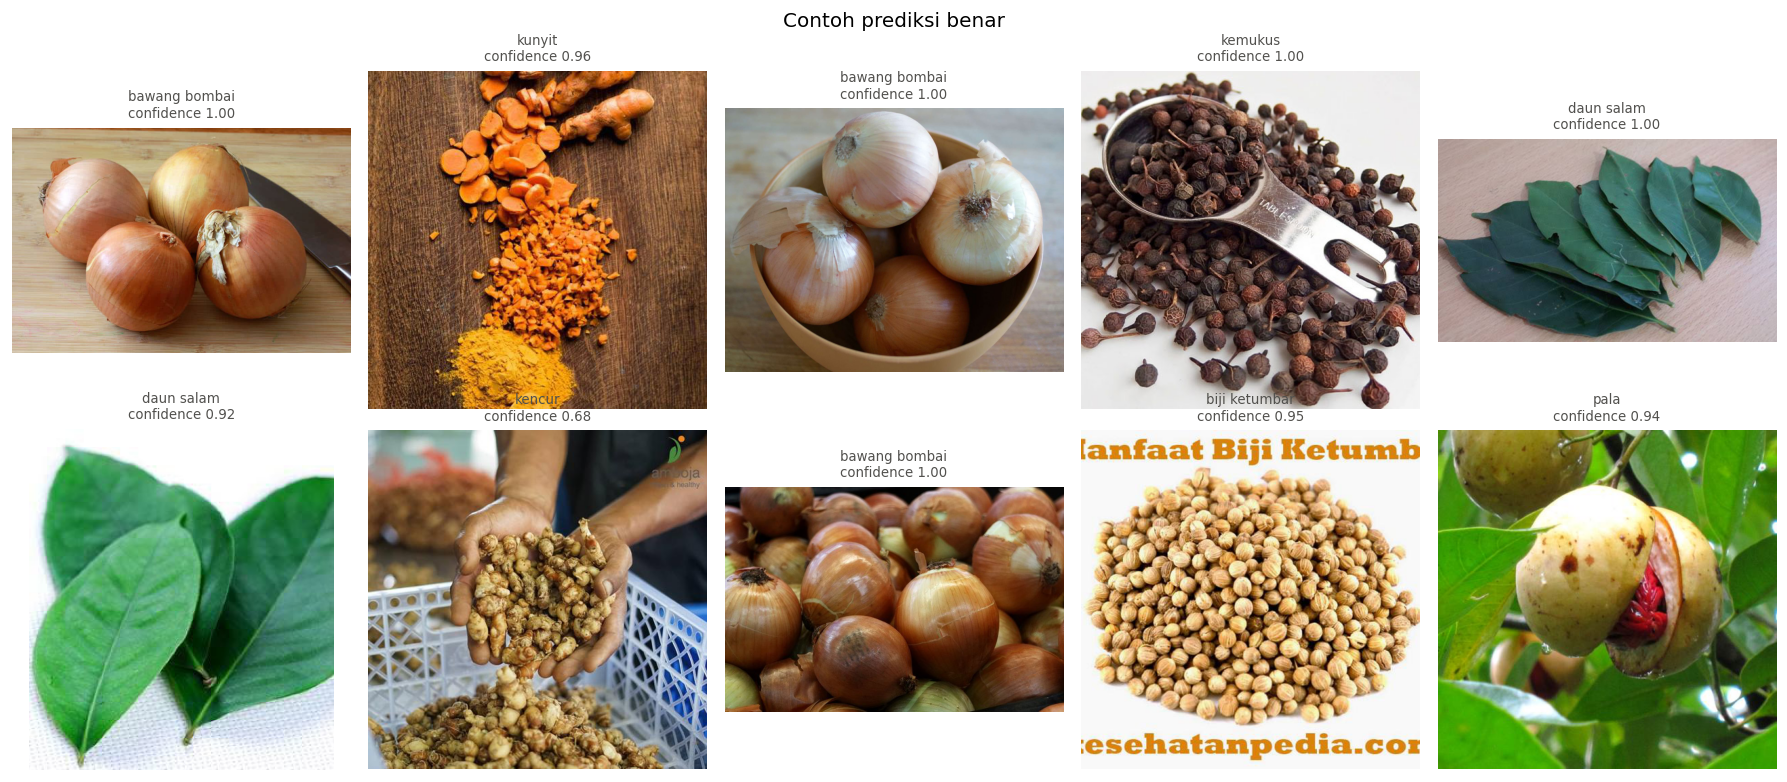

In [12]:
rng = np.random.default_rng(dp.SEED)
benar_idx = np.where(preds == trues)[0]
pilih = rng.choice(benar_idx, 10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for ax, i in zip(axes.ravel(), pilih):
    ax.imshow(Image.open(paths[i]).convert("RGB"))
    ax.set_title(f"{classes[preds[i]]}\nconfidence {conf[i]:.2f}", fontsize=8, color=C_TEXT)
    ax.axis("off")
fig.suptitle("Contoh prediksi benar")
plt.tight_layout()
plt.show()

## 6. Efisiensi Komputasi

In [13]:
eff = pd.DataFrame([
    ("Jumlah parameter", f"{m['total_params']:,} ({m['total_params']/1e6:.2f} M)"),
    ("Ukuran model", f"{m['size_mb']:.1f} MB"),
    ("Epoch dijalankan", f"{m['epochs_run']} (terbaik: epoch {m['best_epoch']})"),
    ("Waktu training total", f"{m['total_train_time_s']/60:.1f} menit"),
    ("Rata-rata waktu/epoch", f"{m['mean_epoch_time_s']:.1f} detik"),
    ("Latensi inferensi", f"{m['infer_latency_ms_per_batch']:.1f} ms/batch "
                          f"({m['infer_latency_ms_per_image']:.2f} ms/citra)"),
    ("Throughput inferensi", f"{m['infer_throughput_img_per_s']:.0f} citra/detik"),
    ("Device", f"{m['device']} — {m['platform']}"),
], columns=["metrik", "nilai"])
print(eff.to_string(index=False))

print(f"\nAkurasi per juta parameter: {m['accuracy'] / (m['total_params']/1e6):.4f}")
print("Angka ini berguna untuk membandingkan efisiensi arsitektur di tahap perbandingan kelompok.")

               metrik                          nilai
     Jumlah parameter         134,387,551 (134.39 M)
         Ukuran model                       537.6 MB
     Epoch dijalankan           5 (terbaik: epoch 5)
 Waktu training total                     17.3 menit
Rata-rata waktu/epoch                    196.4 detik
    Latensi inferensi 299.2 ms/batch (9.35 ms/citra)
 Throughput inferensi                107 citra/detik
               Device     mps — arm64 / torch 2.15.0

Akurasi per juta parameter: 0.0070
Angka ini berguna untuk membandingkan efisiensi arsitektur di tahap perbandingan kelompok.


## 7. Ekspor Hasil

In [14]:
out_dir = Path(evalres["output_dir"])
print(f"Isi {out_dir}:")
for f in sorted(out_dir.iterdir()):
    print(f"  {f.name:28s} {f.stat().st_size/1024:8.1f} KB")

print(f"""
Protokol yang dipakai SAMA dengan train_efficientnet.py:
  - data_split/ hasil dedup ({m['n_train']}/{m['n_val']}/{m['n_test']})
  - dp.build_dataloaders() yang sama (224x224, normalisasi ImageNet, augment="{CONFIG.augment}")
  - TrainConfig yang sama (lr={CONFIG.lr}, epochs={CONFIG.epochs}, batch={CONFIG.batch_size})
  - metrik dihitung oleh tr.evaluate() yang sama

CATATAN untuk laporan:
  - VGG16 dilatih pada batch {CONFIG.batch_size} di mesin ini ({m['platform']}, device {m['device']})
    tanpa masalah memori.
  - Waktu training dan latensi inferensi TIDAK apple-to-apple dengan arsitektur yang dilatih di
    mesin lain. Catat spesifikasi mesin masing-masing di laporan, atau ukur ulang di satu laptop.
  - Perbandingan akurasi/F1 tetap sahih hanya kalau split data identik (cek manifest.csv).
""")

Isi /Users/pangeran/Documents/Telkom University/semester 5/visi komputer/TugasCNN/IndonesiaSpicesProject_CNN/results/vgg16:
  classification_report.txt         1.9 KB
  confusion_matrix.csv              2.2 KB
  history.json                      1.5 KB
  metrics.json                      1.1 KB
  per_class.json                    2.7 KB
  test_preds.npy                    7.2 KB
  test_probs.npy                  109.7 KB
  test_true.npy                     7.2 KB

Protokol yang dipakai SAMA dengan train_efficientnet.py:
  - data_split/ hasil dedup (4219/904/905)
  - dp.build_dataloaders() yang sama (224x224, normalisasi ImageNet, augment="basic")
  - TrainConfig yang sama (lr=0.0001, epochs=5, batch=32)
  - metrik dihitung oleh tr.evaluate() yang sama

CATATAN untuk laporan:
  - VGG16 dilatih pada batch 32 di mesin ini (arm64 / torch 2.15.0, device mps)
    tanpa masalah memori.
  - Waktu training dan latensi inferensi TIDAK apple-to-apple dengan arsitektur yang dilatih di
    mesin la

In [15]:
ringkasan_baris = {
    "arsitektur": MODEL_NAME,
    "params_M": round(m["total_params"] / 1e6, 2),
    "accuracy": round(m["accuracy"], 4),
    "precision_macro": round(m["precision_macro"], 4),
    "recall_macro": round(m["recall_macro"], 4),
    "f1_macro": round(m["f1_macro"], 4),
    "train_time_min": round(m["total_train_time_s"] / 60, 1),
    "infer_ms_per_image": round(m["infer_latency_ms_per_image"], 2),
}
print(pd.DataFrame([ringkasan_baris]).to_string(index=False))

Path("results").mkdir(exist_ok=True)
pd.DataFrame([ringkasan_baris]).to_csv(f"results/{MODEL_NAME}/summary_row.csv", index=False)
print(f"\nDisimpan: results/{MODEL_NAME}/summary_row.csv")

arsitektur  params_M  accuracy  precision_macro  recall_macro  f1_macro  train_time_min  infer_ms_per_image
     vgg16    134.39    0.9348           0.9369        0.9344    0.9342            17.3                9.35

Disimpan: results/vgg16/summary_row.csv


## 8. Ringkasan

- **Performa test:** akurasi 0.9348, macro-F1 0.9342, top-5 0.9967 (59 salah dari 905).
- **Training:** val macro-F1 terbaik 0.9358 di epoch 5. Gap train-val akurasi +0.022 → tidak overfitting;
  val loss masih turun → belum konvergen.
- **Kelas terlemah:** biji ketumbar (0.80), daun kemangi, lengkuas, daun ketumbar (0.87). Kebingungan
  terbesar: daun ketumbar→daun kemangi (6), biji ketumbar→lada (4), kapulaga→biji ketumbar (4).
- **Confidence:** 0.96 saat benar vs 0.74 saat salah.
- **Efisiensi:** 134.4 M parameter, 537.6 MB, training 17.3 menit (M1 Pro), inferensi 9.35 ms/citra.
- **Catatan:** split data VGG16 (4219 / 904 / 905) berbeda tipis dari dua model lain (4221 / 905 / 905).

### Latensi VGG16 vs EfficientNet-B0 (satu perangkat)

In [16]:
baris = []
for name in ["vgg16", "efficientnet_b0"]:
    mdl = tr.build_model(name, num_classes=31, pretrained=False)
    r = tr.measure_inference(mdl, DEVICE, batch_size=32)
    p = tr.count_parameters(mdl)
    baris.append({
        "arsitektur": name,
        "params_M": round(p["total_params"] / 1e6, 1),
        "ms/citra": round(r["latency_ms_per_image"], 2),
        "citra/detik": round(r["throughput_img_per_s"]),
    })
    del mdl

print(f"Perangkat: {DEVICE} (satu laptop yang sama)")
print(pd.DataFrame(baris).to_string(index=False))

Perangkat: mps (satu laptop yang sama)
     arsitektur  params_M  ms/citra  citra/detik
          vgg16     134.4     10.01          100
efficientnet_b0       4.0      2.71          369
